# DATASCI 530 – Assignment 4

**Name:** Parimal Majumder  
**Course:** DATASCI 530  
**Assignment:** Assignment 4  
**Topic:** Regular Expressions and Text Data Analysis

## Introduction

This assignment uses regular expressions to extract information from text data in the `bills_actions.csv` dataset. The analysis includes descriptive statistics, House floor actions, names mentioned in bill actions, Senate amendment activity, and senator coauthor relationships.



## Summary of Findings

The dataset contains 3,303 observations and 1,331 distinct bill identifiers. Amendments are the largest bill category, accounting for 46.29% of observations, while House floor actions are the most common main action at 30.88%.

Among Senate bills with House floor actions, 116 actions were identified. Of these, 68.97% involved suspension and 15.52% were suspended as amended. Regular expressions identified 53 unique people in these House floor actions, with Mr. Takano appearing in the largest number of distinct bills.

For Senate amendments proposed on the floor, 286 action rows corresponded to 127 unique bills. Most bills mentioned two senators. The coauthor analysis showed substantial variation in the number of distinct Senator 2 collaborators associated with each Senator 1.

As an additional insight, McConnell appeared in the largest number of unique Senate amendment bills, followed by Cornyn, while most other senators appeared in far fewer bills.

That will satisfy the assignment requirement for a short fin

## 1. Load the Data

In [208]:
import pandas as pd

bills = pd.read_csv("data_raw/bills_actions.csv")

print("Dataset shape:", bills.shape)
print("\nColumn names:")
print(bills.columns)

bills.head()


Dataset shape: (3303, 7)

Column names:
Index(['Congress', 'bill_number', 'bill_type', 'action', 'main_action',
       'category', 'member_id'],
      dtype='str')


,Congress,bill_number,bill_type,action,main_action,category,member_id
0,116,1029,s,S.Amdt.1274 Amendment SA 1274 proposed by Senator McConnell for Senator Cornyn. (consideration: CR S7233 ; text: CR S7233 ) In the nature of a substitute.,senate amendment proposed (on the floor),amendment,858
1,116,1031,s,S.Amdt.2698 Amendment SA 2698 proposed by Senator Hawley. (consideration: CR S7394-7395 ; text: CR S7394-7395 ) In the nature of a substitute.,senate amendment proposed (on the floor),amendment,675
2,116,1160,s,S.Amdt.2659 Amendment SA 2659 proposed by Senator McConnell for Senator Smith. (consideration: CR S5717 ; text: CR S5717 ) In the nature of a substitute.,senate amendment proposed (on the floor),amendment,858
3,116,1199,s,"Committee on Health, Education, Labor, and Pensions. Reported by Senator Alexander with an amendment in the nature of a substitute. Without written report.",senate committee/subcommittee actions,senate bill,1561
4,116,1208,s,Committee on the Judiciary. Reported by Senator Graham with an amendment in the nature of a substitute. Without written report.,senate committee/subcommittee actions,senate bill,1580


The dataset contains 3,303 observations and 7 variables.

## 2. Basic Descriptive Statistics

I first summarize the dataset by examining the number of distinct bill identifiers and the distribution of observations across bill categories and main action types.

In [209]:
print("Distinct bill identifiers:")
print(bills["bill_number"].nunique())

print("\nCategory proportions:")
print(bills["category"].value_counts(normalize=True))

print("\nMain action proportions:")
print(bills["main_action"].value_counts(normalize=True))

Distinct bill identifiers:
1331

Category proportions:
category
amendment                       0.462913
house bill                      0.273085
senate bill                     0.155616
house resolution                0.070845
senate resolution               0.018165
house joint resolution          0.006661
house concurrent resolution     0.006055
senate concurrent resolution    0.004239
senate joint resolution         0.002422
Name: proportion, dtype: float64

Main action proportions:
main_action
house floor actions                              0.308810
house amendment offered                          0.250681
senate committee/subcommittee actions            0.131396
other house amendment actions                    0.120194
senate amendment proposed (on the floor)         0.086588
house committee/subcommittee actions             0.066001
reported to senate                               0.010899
senate committee report filed after reporting    0.009991
other senate amendment actions  

### Distribution of Main Actions

The following table shows the percentage of observations belonging to each type of main congressional action.

In [210]:
main_action_prop = (
    bills["main_action"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

main_action_prop

main_action
house floor actions                              30.88
house amendment offered                          25.07
senate committee/subcommittee actions            13.14
other house amendment actions                    12.02
senate amendment proposed (on the floor)          8.66
house committee/subcommittee actions              6.60
reported to senate                                1.09
senate committee report filed after reporting     1.00
other senate amendment actions                    0.54
resolving differences -- house actions            0.42
senate floor actions                              0.39
house discharge petition filed                    0.09
resolving differences -- senate actions           0.09
Name: proportion, dtype: float64

### Interpretation

House floor actions are the most common type of main action, accounting for 30.88% of all observations. House amendments offered are the second most common at 25.07%. Together, these two categories make up more than half of the observations in the dataset. Senate committee/subcommittee actions account for 13.14%, while Senate amendments proposed on the floor account for 8.66%.

### Distribution of Bill Categories

The following table shows the percentage of observations belonging to each bill category.


In [211]:
category_prop = (
    bills["category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

category_prop

category
amendment                       46.29
house bill                      27.31
senate bill                     15.56
house resolution                 7.08
senate resolution                1.82
house joint resolution           0.67
house concurrent resolution      0.61
senate concurrent resolution     0.42
senate joint resolution          0.24
Name: proportion, dtype: float64

### Interpretation

Amendments make up the largest share of the dataset, accounting for 46.29% of all observations. House bills are the second largest category at 27.31%, followed by Senate bills at 15.56%. House resolutions account for 7.08%, while all other categories each represent less than 2% of the dataset.

### Distinct Bill Identifiers

The dataset contains 1,331 distinct bill identifiers across 3,303 observations. This indicates that some bills appear multiple times because a bill may have more than one recorded action.

## 3. House Floor Actions for Senate Bills

This section focuses on House floor actions associated with bills in the Senate bill category.

In [212]:
senate_house_floor = bills[
    (bills["category"] == "senate bill") &
    (bills["main_action"] == "house floor actions")
]

senate_house_floor.shape


(116, 7)

In [213]:
senate_house_floor[["bill_number", "action"]].head()

,bill_number,action
559,1436,Ms. Lofgren asked unanimous consent to take from the Speaker's table and consider.
560,1693,Mr. Evans asked unanimous consent to take from the Speaker's table and consider.
562,1749,Mr. Clay asked unanimous consent to discharge from committee and consider.
563,2047,Ms. DeGette asked unanimous consent to take from the Speaker's table and consider.
564,2249,Mr. Larsen (WA) asked unanimous consent to discharge from committee and consider.


The filtered dataset contains 116 House floor actions associated with Senate bills.

In [214]:
suspended = senate_house_floor["action"].str.contains(
    r"suspend",
    case=False,
    na=False
)

suspended_as_amended = senate_house_floor["action"].str.contains(
    r"suspend.*as amended",
    case=False,
    na=False
)

print("Proportion suspended:")
print(round(suspended.mean() * 100, 2))

print("\nProportion suspended as amended:")
print(round(suspended_as_amended.mean() * 100, 2))

Proportion suspended:
68.97

Proportion suspended as amended:
15.52


### Interpretation

Among the 116 House floor actions associated with Senate bills, 68.97% involved suspension. Of all 116 actions, 15.52% were suspended as amended. This shows that suspension was common among these House floor actions, while a smaller subset specifically involved suspension as amended.

### Extracting Names from House Floor Actions

The House floor action text identifies specific people using titles such as Mr., Ms., and Mrs. I use a regular expression to extract these names and then count how many bills mention each person.

In [215]:
name_pattern = r"\b(?:Mr|Ms|Mrs)\.\s+[A-Z][A-Za-z'-]+"

senate_house_floor["person"] = (
    senate_house_floor["action"]
    .str.extract(f"({name_pattern})", expand=False)
)

senate_house_floor[["bill_number", "person", "action"]].head(10)

,bill_number,person,action
559,1436,Ms. Lofgren,Ms. Lofgren asked unanimous consent to take from the Speaker's table and consider.
560,1693,Mr. Evans,Mr. Evans asked unanimous consent to take from the Speaker's table and consider.
562,1749,Mr. Clay,Mr. Clay asked unanimous consent to discharge from committee and consider.
563,2047,Ms. DeGette,Ms. DeGette asked unanimous consent to take from the Speaker's table and consider.
564,2249,Mr. Larsen,Mr. Larsen (WA) asked unanimous consent to discharge from committee and consider.
565,3147,Mrs. Luria,Mrs. Luria moved to suspend the rules and pass the bill.
566,3201,Ms. Kuster,Ms. Kuster (NH) moved to suspend the rules and pass the bill.
567,3414,Mr. Takano,Mr. Takano moved to suspend the rules and pass the bill.
568,3503,Mr. Raskin,Mr. Raskin asked unanimous consent to take from the Speaker's table and consider.
569,3587,Mrs. Luria,Mrs. Luria moved to suspend the rules and pass the bill.


### Number of Bills Mentioned per Person

After extracting the names, I count the number of distinct bills associated with each person. Using distinct bill numbers prevents multiple actions for the same bill from being counted more than once.


In [216]:
person_bill_counts = (
    senate_house_floor
    .dropna(subset=["person"])
    .groupby("person")["bill_number"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="number_of_bills")
)

person_bill_counts.head(10)

,person,number_of_bills
0,Mr. Takano,9
1,Ms. Haaland,6
2,Mrs. Dingell,6
3,Mr. Case,5
4,Ms. Kelly,5
5,Mr. Pallone,5
6,Ms. Bass,5
7,Mr. DeFazio,4
8,Mr. Cicilline,4
9,Ms. Norton,4


In [217]:
person_bill_counts.shape

(53, 2)

The name extraction identified 53 unique people mentioned in the House floor actions.

In [218]:
bill_distribution = (
    person_bill_counts["number_of_bills"]
    .value_counts()
    .sort_index()
    .reset_index()
)

bill_distribution.columns = ["number_of_bills", "number_of_people"]

bill_distribution

,number_of_bills,number_of_people
0,1,29
1,2,10
2,3,3
3,4,4
4,5,4
5,6,2
6,9,1


### Interpretation

Most people were mentioned in only one bill. Specifically, 29 of the 53 unique people were associated with one bill, while 10 people were associated with two bills. Only a small number of people appeared in several bills, and one person was associated with as many as nine bills. This indicates that the distribution is concentrated toward lower numbers of bills per person.

In [219]:
person_bill_counts.head(10)

,person,number_of_bills
0,Mr. Takano,9
1,Ms. Haaland,6
2,Mrs. Dingell,6
3,Mr. Case,5
4,Ms. Kelly,5
5,Mr. Pallone,5
6,Ms. Bass,5
7,Mr. DeFazio,4
8,Mr. Cicilline,4
9,Ms. Norton,4


### Interpretation

Mr. Takano was associated with the largest number of distinct bills, appearing in 9 bills. Ms. Haaland and Mrs. Dingell each appeared in 6 bills, while several other members appeared in 4 or 5 bills. Overall, most people were associated with relatively few bills, with only a small number appearing repeatedly across multiple bills.

## 4. Senate Amendments Proposed on the Floor

This section focuses on bills whose main action is classified as "senate amendment proposed (on the floor)." I examine how many senators are mentioned in each bill and identify the first and second senator mentioned.

In [220]:
senate_amendments = bills[
    bills["main_action"] == "senate amendment proposed (on the floor)"
].copy()

senate_amendments.shape

senate_amendments[["bill_number", "action"]].head(10)

,bill_number,action
0,1029,S.Amdt.1274 Amendment SA 1274 proposed by Senator McConnell for Senator Cornyn. (consideration: CR S7233 ; text: CR S7233 ) In the nature of a substitute.
1,1031,S.Amdt.2698 Amendment SA 2698 proposed by Senator Hawley. (consideration: CR S7394-7395 ; text: CR S7394-7395 ) In the nature of a substitute.
2,1160,S.Amdt.2659 Amendment SA 2659 proposed by Senator McConnell for Senator Smith. (consideration: CR S5717 ; text: CR S5717 ) In the nature of a substitute.
8,1253,S.Amdt.2424 Amendment SA 2424 proposed by Senator Feinstein for Senator Cornyn. (consideration: CR S4174-4175 ; text: CR S4174-4175 ) To require the National Institutes of Health to conduct a study and report on the short-term and long-term health impacts of e-cigarette use by youth and young adults under 21 years of age.
11,1309,S.Amdt.1275 Amendment SA 1275 proposed by Senator McConnell for Senator Cardin. (consideration: CR S7236 ; text: CR S7220-7221 ) In the nature of a substitute.
14,1340,S.Amdt.940 Amendment SA 940 proposed by Senator Rubio for Senator Menendez. (consideration: CR S5633 ; text: CR S5633 ) To modify the authority to provide assistance.
17,1387,S.Amdt.2710 Amendment SA 2710 proposed by Senator Moran for Senator Braun. (consideration: CR S7557 ; text: CR S7554-7555 ) In the nature of a substitute.
18,1434,S.Amdt.1269 Amendment SA 1269 proposed by Senator McConnell for Senator Portman. (consideration: CR S7229 ; text: CR S7229 ) To modify the definition of reverse auction to cover the awarding of contracts and orders that are based solely on the price obtained through the auction process.
20,1430,S.Amdt.1251 Amendment SA 1251 proposed by Senator Fischer for Senator Lankford. (consideration: CR S6766 ; text: CR S6766 ) To make certain corrections.
26,1636,S.Amdt.2707 Amendment SA 2707 proposed by Senator McConnell for Senator Alexander. (consideration: CR S7470 ; text: CR S7470 ) In the nature of a substitute.


### Extracting Senators from Senate Amendment Actions

The action text may mention one or more senators using the pattern "Senator [Name]". I use a regular expression to extract all senator names from each action, then count how many senators are mentioned and identify the first two senators listed.

In [221]:
senator_pattern = r"Senator\s+([A-Z][A-Za-z'-]+(?:\s+[A-Z][A-Za-z'-]+)*)"

senate_amendments["senators"] = (
    senate_amendments["action"]
    .str.findall(senator_pattern)
)

senate_amendments["number_of_senators"] = (
    senate_amendments["senators"]
    .str.len()
)

senate_amendments["Senator_1"] = (
    senate_amendments["senators"]
    .str[0]
)

senate_amendments["Senator_2"] = (
    senate_amendments["senators"]
    .str[1]
)

senate_amendments[
    ["bill_number", "number_of_senators", "Senator_1", "Senator_2"]
].head(10)

,bill_number,number_of_senators,Senator_1,Senator_2
0,1029,2,McConnell,Cornyn
1,1031,1,Hawley,NaN
2,1160,2,McConnell,Smith
8,1253,2,Feinstein,Cornyn
11,1309,2,McConnell,Cardin
14,1340,2,Rubio,Menendez
17,1387,2,Moran,Braun
18,1434,2,McConnell,Portman
20,1430,2,Fischer,Lankford
26,1636,2,McConnell,Alexander


In [222]:
print("Number of rows:", len(senate_amendments))
print("Number of unique bills:", senate_amendments["bill_number"].nunique())

Number of rows: 286
Number of unique bills: 127


In [223]:
senate_amendments["bill_number"].duplicated().sum()

np.int64(159)

### Creating a Bill-Level Senator Dataset

Because some bills have multiple Senate amendment action rows, I aggregate the data by bill number. I combine the senators mentioned across all actions for each bill and remove duplicate senator names while preserving their order of appearance.

In [224]:
def unique_in_order(names):
    return list(dict.fromkeys(
        name
        for group in names
        for name in group
    ))

senate_bill_summary = (
    senate_amendments
    .groupby("bill_number")["senators"]
    .apply(unique_in_order)
    .reset_index(name="senators")
)

senate_bill_summary["number_of_senators"] = (
    senate_bill_summary["senators"].str.len()
)

senate_bill_summary["Senator_1"] = senate_bill_summary["senators"].str[0]
senate_bill_summary["Senator_2"] = senate_bill_summary["senators"].str[1]

In [225]:
senate_bill_summary.shape

(127, 5)

### Distribution of Senators per Bill

The following table summarizes how many unique senators are mentioned per bill after combining all Senate amendment action rows for each bill.

In [226]:
senator_distribution = (
    senate_bill_summary["number_of_senators"]
    .value_counts()
    .sort_index()
    .reset_index()
)

senator_distribution.columns = [
    "number_of_senators",
    "number_of_bills"
]

senator_distribution

,number_of_senators,number_of_bills
0,1,21
1,2,92
2,3,5
3,4,5
4,5,1
5,7,1
6,30,1
7,38,1


### Interpretation

Most Senate amendment bills mention two senators. Of the 127 unique bills, 92 mention two senators and 21 mention only one senator. Only a small number of bills mention three or more senators. A few bills contain unusually large numbers of senator mentions, including one bill with 30 senators and another with 38 senators.

In [227]:
coauthor_counts = (
    senate_bill_summary
    .dropna(subset=["Senator_2"])
    .groupby("Senator_1")["Senator_2"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="number_of_different_coauthors")
)

coauthor_counts.head(10)

,Senator_1,number_of_different_coauthors
0,McConnell,37
1,Cornyn,9
2,Murkowski,6
3,Braun,5
4,Sasse,3
5,Paul,3
6,Sullivan,2
7,Rubio,2
8,Moran,2
9,Lee,2


### Interpretation

The number of different coauthors varies considerably across senators. McConnell has the largest number of distinct Senator 2 coauthors, with 37 different people appearing alongside him. Cornyn follows with 9, while Murkowski has 6 and Braun has 5. Most of the remaining senators have only a small number of distinct coauthors.

## 5. New Insight: Senators Most Frequently Mentioned Across Bills


In [228]:
senator_bill_counts = (
    senate_bill_summary
    .explode("senators")
    .groupby("senators")["bill_number"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="number_of_bills")
)

senator_bill_counts.head(10)

,senators,number_of_bills
0,McConnell,64
1,Cornyn,18
2,Moran,9
3,Murkowski,9
4,Paul,9
5,Rubio,8
6,Peters,7
7,Alexander,7
8,Shelby,6
9,Lee,6


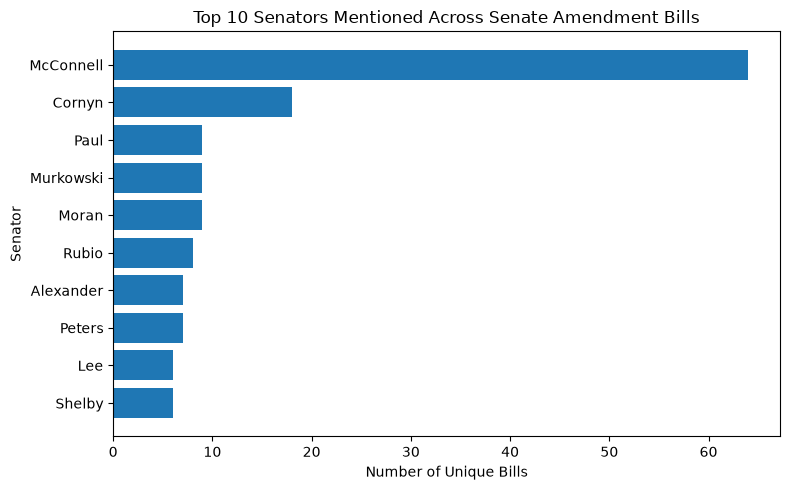

In [229]:
import matplotlib.pyplot as plt

top_senators = senator_bill_counts.head(10).sort_values(
    "number_of_bills",
    ascending=True
)

plt.figure(figsize=(8, 5))

plt.barh(
    top_senators["senators"],
    top_senators["number_of_bills"]
)

plt.xlabel("Number of Unique Bills")
plt.ylabel("Senator")
plt.title("Top 10 Senators Mentioned Across Senate Amendment Bills")

plt.tight_layout()
plt.show()

### Interpretation

McConnell appears in the largest number of unique Senate amendment bills, with 64 bills, substantially more than any other senator. Cornyn appears in 18 bills, while the remaining senators in the top ten appear in fewer than 10 bills each. This suggests that senator mentions are highly concentrated among a small number of individuals, with McConnell appearing particularly frequently across Senate amendment actions.